# Disease Risk Prediction: Diabetes (Pima Indians Diabetes Data)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sayleeraut/disease-risk-prediction/blob/main/diabetes_risk_prediction.ipynb)

## 1. Project goal

Type 2 diabetes often goes unnoticed for years. A model that flags patients at **high risk of diabetes** from routine measurements (glucose, BMI, blood pressure, age, etc.) can help doctors decide **who should be tested further**.

In this notebook I:

1. **clean** the data, in particular the **physiologically impossible values** (such as a blood pressure of 0),
2. explore how each measurement relates to diabetes,
3. **normalise** the features and compare **five classification models**,
4. analyse **feature importance** and choose a **screening threshold** with high sensitivity,
5. discuss **ethical data handling, bias and patient privacy**.

## 2. Dataset description and source

The **Pima Indians Diabetes Database** was originally collected by the **US National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK)** and first used by Smith et al. (1988). It is a classic UCI/Kaggle benchmark.

- **Population:** 768 **female** patients aged 21 or older, of **Pima Indian heritage** (Gila River community, Arizona)
- **Target:** `Outcome` = 1 if the patient was diagnosed with diabetes within five years
- **Source used here:** public CSV copy in [jbrownlee/Datasets](https://github.com/jbrownlee/Datasets/blob/master/pima-indians-diabetes.data.csv), with a fallback to [OpenML dataset 37](https://www.openml.org/d/37). Also on [Kaggle](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database).

| Column | Meaning |
|---|---|
| `Pregnancies` | number of times pregnant |
| `Glucose` | plasma glucose concentration 2 hours after an oral glucose tolerance test (mg/dL) |
| `BloodPressure` | diastolic blood pressure (mm Hg) |
| `SkinThickness` | triceps skin-fold thickness (mm) |
| `Insulin` | 2-hour serum insulin (μU/mL) |
| `BMI` | body mass index (kg/m²) |
| `DiabetesPedigreeFunction` | score for family history of diabetes |
| `Age` | age in years |
| `Outcome` | 1 = diabetes, 0 = no diabetes |

The data is **already de-identified**: it contains no names, IDs or dates.

## 3. Setup and imports

In [1]:
import sys

# Install the needed packages only when running inside Google Colab
if "google.colab" in sys.modules:
    %pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost

In [2]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

os.makedirs("images", exist_ok=True)

# Plot style: fixed categorical palette, light grid, no top/right spines
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "lines.linewidth": 2, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## 4. Data loading

In [3]:
COLUMNS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
           "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
PRIMARY_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

try:
    df = pd.read_csv(PRIMARY_URL, header=None, names=COLUMNS)
    print("Loaded from GitHub (jbrownlee/Datasets)")
except Exception as e:
    # Fallback: the same data hosted on OpenML (dataset 37)
    from sklearn.datasets import fetch_openml
    raw = fetch_openml(data_id=37, as_frame=True).frame
    raw["class"] = (raw["class"] == "tested_positive").astype(int)
    df = raw.set_axis(COLUMNS, axis=1)
    print("Loaded from OpenML, reason:", e)

print("Shape:", df.shape)
df.head()

Loaded from GitHub (jbrownlee/Datasets)
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


The summary already shows a problem: **Glucose, BloodPressure, SkinThickness, Insulin and BMI all have a minimum of 0**. A living person cannot have a glucose level, blood pressure or BMI of 0. These zeros are really **missing measurements** that were recorded as 0.

## 5. Data cleaning

### 5.1 Impossible zero values

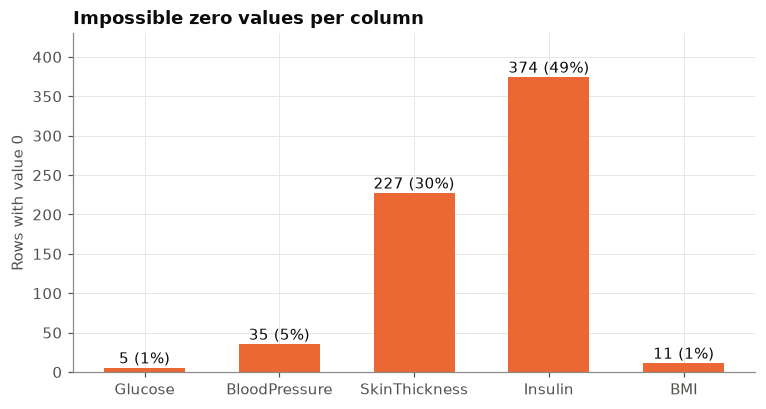

In [5]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[ZERO_AS_MISSING] == 0).sum()
zero_pct = zero_counts / len(df)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(zero_counts.index, zero_counts.values, color=PALETTE[1], width=0.6)
for b, n, p in zip(bars, zero_counts.values, zero_pct.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 6, f"{n} ({p:.0%})", ha="center")
ax.set_ylim(0, zero_counts.max() * 1.15)
ax.set_ylabel("Rows with value 0")
ax.set_title("Impossible zero values per column")
plt.savefig("images/impossible_zeros.png")
plt.show()

**Observation:** **Insulin** is 0 for almost half the patients (49%) and **SkinThickness** for about 30%, so these tests were simply not done for many patients. Glucose (5 rows), BMI (11) and BloodPressure (35) have only a few zeros. `Pregnancies = 0` is a **valid** value (the patient has never been pregnant), so I leave it alone.

**Cleaning plan**
1. Replace the impossible zeros with **NaN** (missing).
2. **Impute** the missing values with the **median** of the *training* data. The median is robust to the skewed Insulin and SkinThickness distributions. To avoid **data leakage**, the imputer runs inside the modelling pipeline, so it learns only from the training set. I do *not* impute per outcome class, because that would use the label.
3. **Normalise** all features with `StandardScaler` (mean 0, standard deviation 1), also inside the pipeline. This is essential for distance-based models (KNN, SVM) and for comparing Logistic Regression coefficients.
4. Check for duplicates and implausible values.

In [6]:
df_clean = df.copy()
df_clean[ZERO_AS_MISSING] = df_clean[ZERO_AS_MISSING].replace(0, np.nan)

print("Duplicate rows:", df_clean.duplicated().sum())
print("\nMissing values after converting impossible zeros:")
print(df_clean.isna().sum().to_frame("missing").assign(pct=lambda t: (t.missing / len(df_clean) * 100).round(1)))
df_clean.describe().T[["min", "50%", "max"]].round(1)

Duplicate rows: 0

Missing values after converting impossible zeros:
                          missing   pct
Pregnancies                     0   0.0
Glucose                         5   0.7
BloodPressure                  35   4.6
SkinThickness                 227  29.6
Insulin                       374  48.7
BMI                            11   1.4
DiabetesPedigreeFunction        0   0.0
Age                             0   0.0
Outcome                         0   0.0


,min,50%,max
Pregnancies,0.0,3.0,17.0
Glucose,44.0,117.0,199.0
BloodPressure,24.0,72.0,122.0
SkinThickness,7.0,29.0,99.0
Insulin,14.0,125.0,846.0
BMI,18.2,32.3,67.1
DiabetesPedigreeFunction,0.1,0.4,2.4
Age,21.0,29.0,81.0
Outcome,0.0,0.0,1.0


There are no duplicates. After the conversion, the remaining value ranges are plausible: glucose 44-199 mg/dL, diastolic blood pressure 24-122 mm Hg, and BMI 18-67. A few values are extreme but medically possible, such as very high insulin readings, so I keep them rather than delete real patients.

## 6. Exploratory Data Analysis

### 6.1 Outcome balance

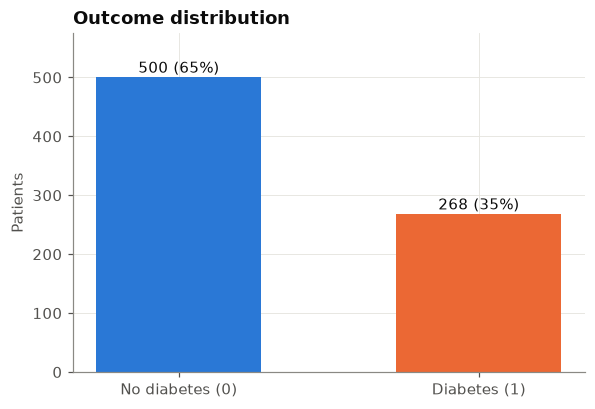

In [7]:
counts = df_clean["Outcome"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No diabetes (0)", "Diabetes (1)"], counts.values, color=[PALETTE[0], PALETTE[1]], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v} ({v / len(df_clean):.0%})", ha="center")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Patients")
ax.set_title("Outcome distribution")
plt.savefig("images/outcome_balance.png")
plt.show()

**Observation:** **268 of 768 patients (35%)** have diabetes. The classes are moderately imbalanced. I use **stratified** splits, so every subset keeps this ratio, and I track **recall (sensitivity)** and ROC-AUC in addition to accuracy.

### 6.2 Feature distributions by outcome

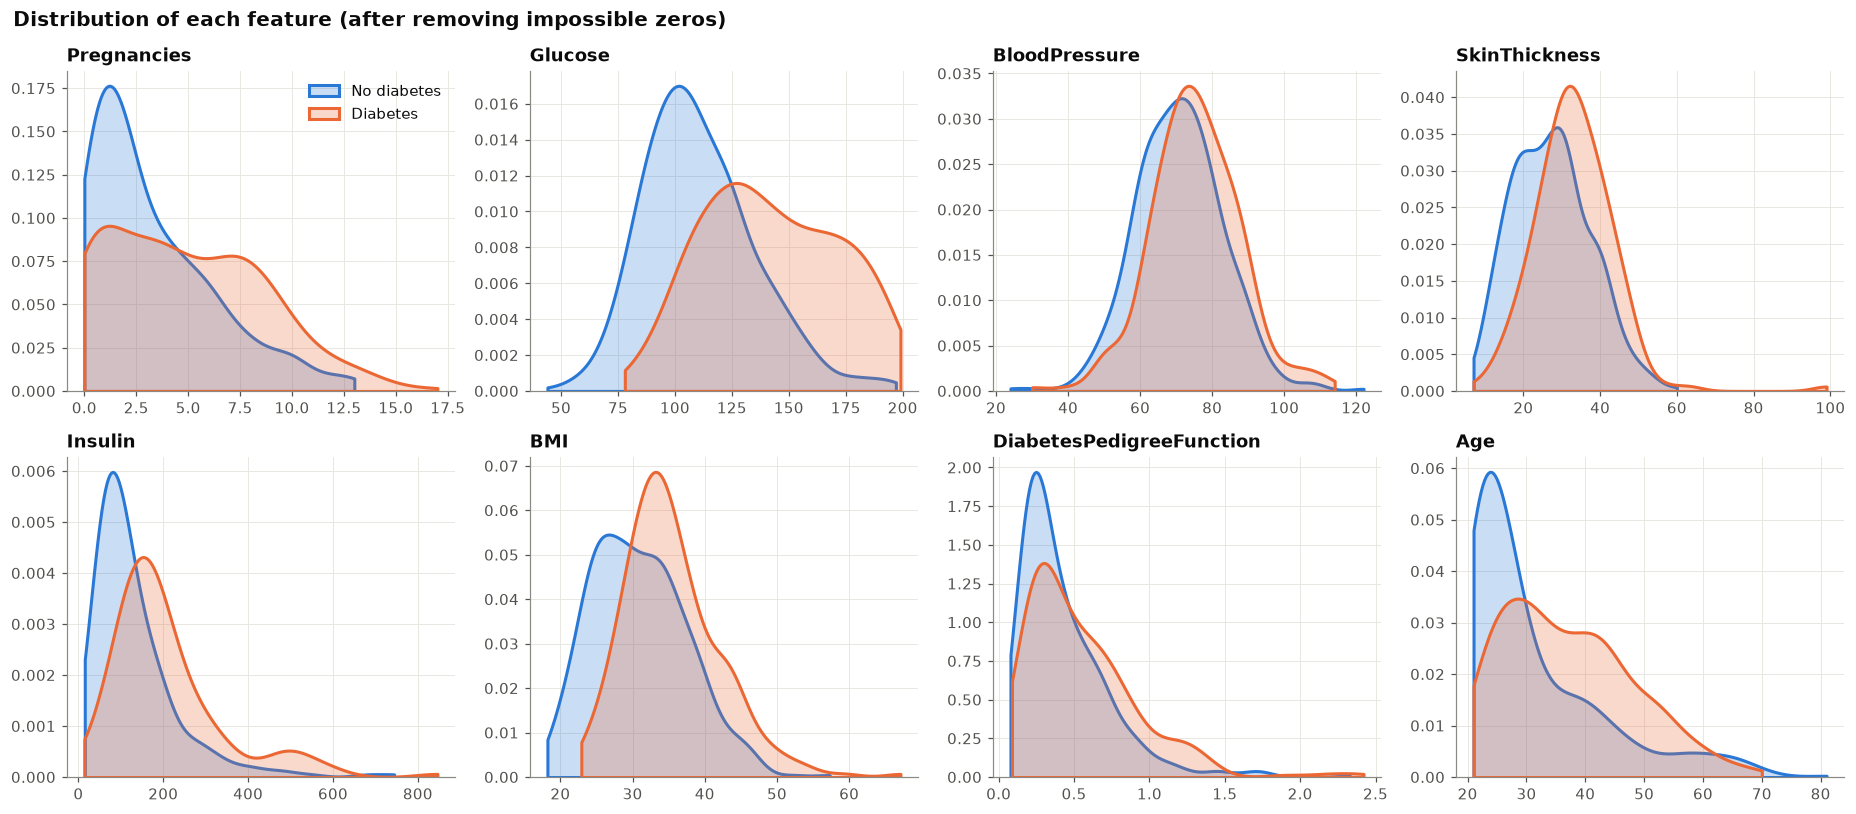

Outcome,No diabetes,Diabetes
Pregnancies,2.0,4.0
Glucose,107.0,140.0
BloodPressure,70.0,74.5
SkinThickness,27.0,32.0
Insulin,102.5,169.5
BMI,30.1,34.3
DiabetesPedigreeFunction,0.3,0.4
Age,27.0,36.0


In [8]:
features = [c for c in df_clean.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, col in zip(axes.ravel(), features):
    for label, color, name in [(0, PALETTE[0], "No diabetes"), (1, PALETTE[1], "Diabetes")]:
        sns.kdeplot(df_clean.loc[df_clean["Outcome"] == label, col].dropna(), ax=ax, color=color,
                    fill=True, alpha=0.25, lw=2, label=name, cut=0)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[0, 0].legend()
plt.suptitle("Distribution of each feature (after removing impossible zeros)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("images/feature_distributions.png")
plt.show()

df_clean.groupby("Outcome")[features].median().T.rename(columns={0: "No diabetes", 1: "Diabetes"}).round(1)

**Observation:**
- **Glucose** separates the groups most clearly. The median is about **140 mg/dL for diabetic patients against 107** for non-diabetic patients.
- **BMI** is also higher in the diabetes group (median about 34 against 30).
- **Age** and **pregnancies** are higher for diabetic patients. Older women with more pregnancies are at higher risk.
- **Insulin** and **SkinThickness** differ less. They also have many missing values, so their signal is weaker.
- **Blood pressure** distributions overlap almost completely.

### 6.3 Glucose vs BMI

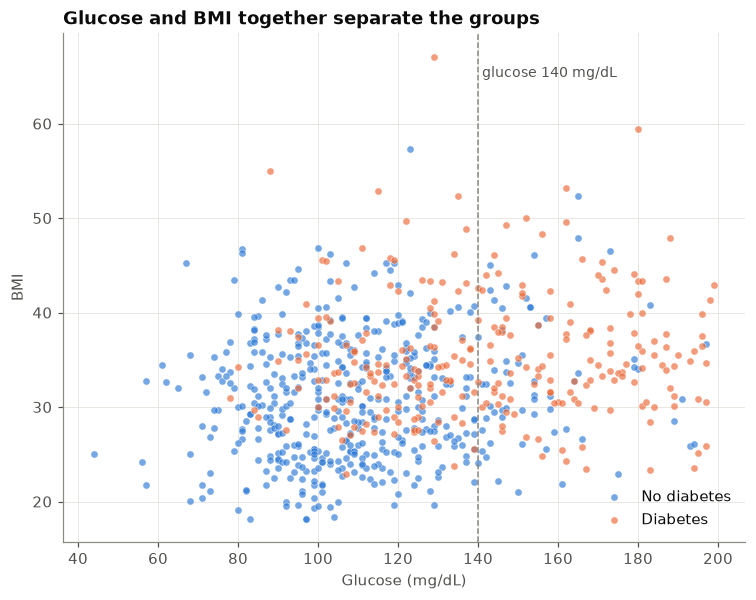

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in [(0, PALETTE[0], "No diabetes"), (1, PALETTE[1], "Diabetes")]:
    sub = df_clean[df_clean["Outcome"] == label]
    ax.scatter(sub["Glucose"], sub["BMI"], s=22, alpha=0.65, color=color, label=name,
               edgecolor="white", linewidth=0.4)
ax.axvline(140, color="#8a8984", ls="--", lw=1)
ax.text(141, df_clean["BMI"].max() - 1, "glucose 140 mg/dL", color="#52514e", fontsize=9, va="top")
ax.set_xlabel("Glucose (mg/dL)")
ax.set_ylabel("BMI")
ax.set_title("Glucose and BMI together separate the groups")
ax.legend(loc="lower right")
plt.savefig("images/glucose_bmi_scatter.png")
plt.show()

**Observation:** most diabetic patients (orange) sit at **high glucose (above about 140 mg/dL, the 2-hour glucose cut-off for impaired glucose tolerance) combined with a BMI above 30** (obesity). Patients with low glucose and normal BMI are almost all non-diabetic. The two groups still overlap in the middle range, which is where the models have to work hardest.

### 6.4 Diabetes rate by age group

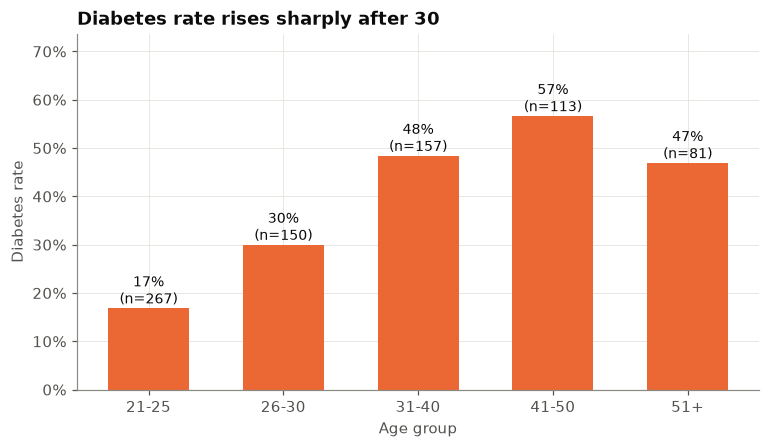

In [10]:
age_band = pd.cut(df_clean["Age"], bins=[20, 25, 30, 40, 50, 90], labels=["21-25", "26-30", "31-40", "41-50", "51+"])
rate = df_clean.groupby(age_band, observed=True)["Outcome"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(rate.index.astype(str), rate["mean"], color=PALETTE[1], width=0.6)
for b, (r, n) in zip(bars, rate.values):
    ax.text(b.get_x() + b.get_width() / 2, r + 0.01, f"{r:.0%}\n(n={int(n)})", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylim(0, rate["mean"].max() * 1.3)
ax.set_xlabel("Age group")
ax.set_ylabel("Diabetes rate")
ax.set_title("Diabetes rate rises sharply after 30")
plt.savefig("images/diabetes_by_age.png")
plt.show()

**Observation:** only about **17%** of the 21-25 year-olds have diabetes, while **about half (48-57%) of patients aged 31-50** do. The rate drops slightly after 50 (47%). The youngest group is also the largest, which matters for the bias check in the ethics section: a model can behave differently for younger and older patients.

### 6.5 Correlation heatmap

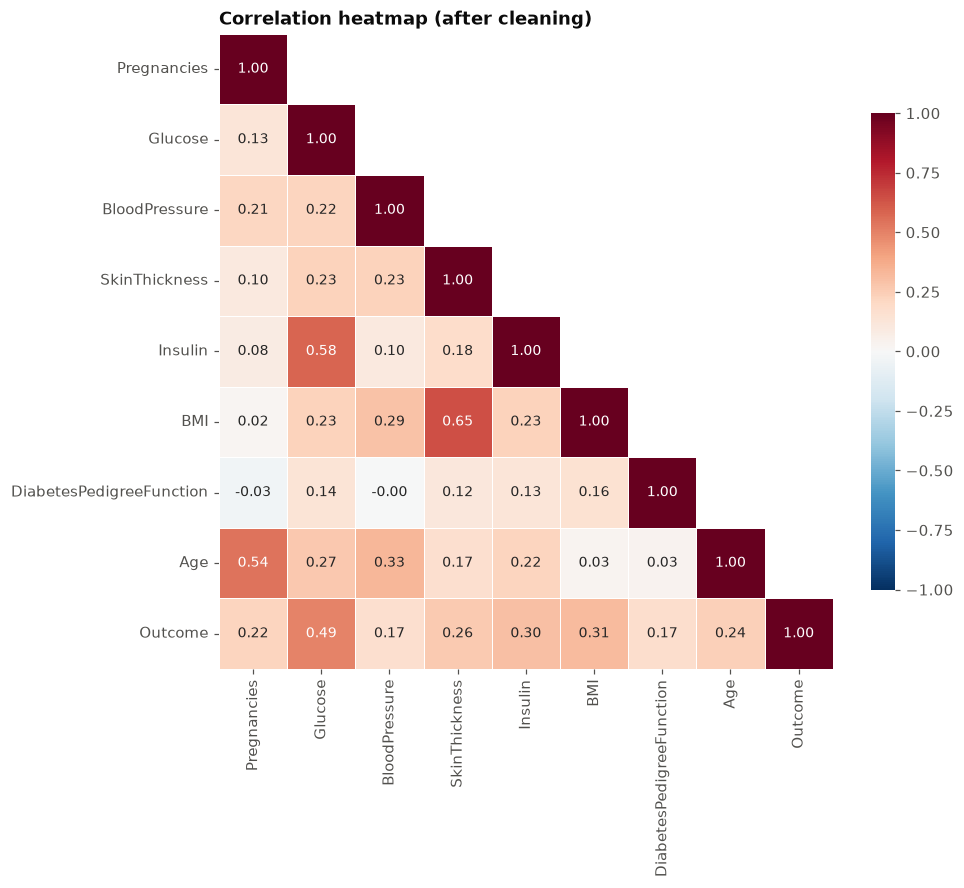

Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64

In [11]:
corr = df_clean.corr()     # pairwise, ignores missing values
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax, annot_kws={"size": 9})
ax.set_title("Correlation heatmap (after cleaning)")
ax.grid(False)
plt.savefig("images/correlation_heatmap.png")
plt.show()
corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

**Observation:**
- **Glucose** has by far the strongest correlation with diabetes (about 0.49), followed by **BMI**, **Age**, **Insulin** and **Pregnancies**.
- Several features are related to each other:
  - **Age and Pregnancies** (about 0.54): older women have had more pregnancies.
  - **BMI and SkinThickness** (about 0.65): both measure body fat.
  - **Glucose and Insulin** (about 0.58): both come from the same glucose tolerance test.
- These overlaps mean some features carry similar information, which is useful to know when interpreting feature importance.

## 7. Modeling

### 7.1 Train/test split and preprocessing pipeline

- **80/20 stratified split** (614 training and 154 test patients).
- Pipeline for every model: **median imputation → standardisation → classifier**. Both steps are learned from the training data only.
- `class_weight="balanced"` (or `scale_pos_weight` for XGBoost) makes the models pay more attention to diabetic patients. KNN has no weighting option.

In [12]:
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "diabetes rate %.2f" % y_train.mean())
print("Test: ", X_test.shape, "diabetes rate %.2f" % y_test.mean())

def make_pipe(model):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("model", model)])

# Show the normalisation effect on the training data
prep_demo = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
X_train_scaled = pd.DataFrame(prep_demo.fit_transform(X_train), columns=X.columns)
X_train_scaled.describe().T[["mean", "std", "min", "max"]].round(2)

Train: (614, 8) diabetes rate 0.35
Test:  (154, 8) diabetes rate 0.35


,mean,std,min,max
Pregnancies,-0.0,1.0,-1.15,3.98
Glucose,-0.0,1.0,-2.19,2.58
BloodPressure,0.0,1.0,-3.92,4.07
SkinThickness,-0.0,1.0,-2.48,7.87
Insulin,-0.0,1.0,-1.56,7.70
BMI,0.0,1.0,-2.09,5.08
DiabetesPedigreeFunction,-0.0,1.0,-1.19,5.61
Age,-0.0,1.0,-1.05,4.03


After imputation and scaling, every feature has **mean 0 and standard deviation 1** in the training set, so no feature dominates just because of its units (insulin in the hundreds, the pedigree score below 2.5).

### 7.2 Five classification models with hyperparameter tuning

| Model | Idea |
|---|---|
| Logistic Regression | linear, interpretable baseline |
| K-Nearest Neighbours | classifies a patient like the most similar patients |
| Support Vector Machine (RBF) | flexible non-linear boundary |
| Random Forest | ensemble of decision trees |
| XGBoost | gradient-boosted trees |

Each model is tuned with a **5-fold stratified grid search** on ROC-AUC, using the training set only.

In [13]:
neg, pos = np.bincount(y_train)
specs = {
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "KNN": (KNeighborsClassifier(),
            {"model__n_neighbors": [5, 11, 15, 21, 31], "model__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED),
                  {"model__C": [0.1, 0.3, 1, 3, 10], "model__gamma": ["scale", 0.03, 0.1]}),
    "Random Forest": (RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED, n_jobs=-1),
                      {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 5, 10]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", scale_pos_weight=neg / pos, random_state=SEED, n_jobs=-1),
                {"model__n_estimators": [100, 300], "model__max_depth": [2, 3, 4],
                 "model__learning_rate": [0.03, 0.1], "model__subsample": [0.8]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
best_models, cv_scores = {}, {}
for name, (model, grid) in specs.items():
    search = GridSearchCV(make_pipe(model), grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    cv_scores[name] = search.best_score_
    print(f"{name:<20} CV ROC-AUC = {search.best_score_:.3f} | {search.best_params_}")

Logistic Regression  CV ROC-AUC = 0.845 | {'model__C': 0.1}


KNN                  CV ROC-AUC = 0.834 | {'model__n_neighbors': 21, 'model__weights': 'distance'}


SVM (RBF)            CV ROC-AUC = 0.845 | {'model__C': 0.3, 'model__gamma': 0.03}


Random Forest        CV ROC-AUC = 0.840 | {'model__max_depth': 6, 'model__min_samples_leaf': 10}


XGBoost              CV ROC-AUC = 0.840 | {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 0.8}


All five models reach a cross-validated ROC-AUC between **0.834 and 0.845**. **Logistic Regression and the SVM tie for first place (0.845)**, the two tree ensembles score 0.840 and KNN 0.834. With only 614 training patients, these differences are well within the noise. That suggests the signal in this dataset is mostly simple and close to linear, driven by glucose and BMI.

## 8. Evaluation

### 8.1 Results table (test set, threshold 0.5)

In [14]:
rows, probas = [], {}
for name, pipe in best_models.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    probas[name] = proba
    rows.append({"Model": name, "CV ROC-AUC": cv_scores[name],
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall (sensitivity)": recall_score(y_test, pred), "Specificity": tn / (tn + fp),
                 "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results.to_csv("images/results_table.csv")
results

,CV ROC-AUC,Accuracy,Precision,Recall (sensitivity),Specificity,F1,ROC-AUC
Model,,,,,,,
Logistic Regression,0.845,0.708,0.571,0.667,0.73,0.615,0.810
KNN,0.834,0.753,0.682,0.556,0.86,0.612,0.812
SVM (RBF),0.845,0.727,0.625,0.556,0.82,0.588,0.803
Random Forest,0.840,0.727,0.586,0.759,0.71,0.661,0.817
XGBoost,0.840,0.760,0.627,0.778,0.75,0.694,0.818


**Reading the table**
- On the test set (154 patients, 54 with diabetes), all models land within **0.015 ROC-AUC** of each other (0.803-0.818).
- **XGBoost** scores highest at the default 0.5 threshold, with **ROC-AUC 0.818, F1 0.694 and sensitivity 0.778**. Random Forest is second.
- **KNN and SVM** have high specificity (0.82-0.86) but miss almost half of the diabetic patients at 0.5. The SVM's probabilities come from Platt scaling, which ignores the class weights, so 0.5 is a conservative threshold for it.

The differences are this small and the test set is small, so I do **not** pick a winner from the test set. For the screening model I choose **Logistic Regression**: it is tied for the best cross-validated AUC (0.845), and it is **fully interpretable**, because a doctor can see exactly how each measurement contributes. The real gain comes from choosing the right threshold, which I do next.

### 8.2 ROC curves

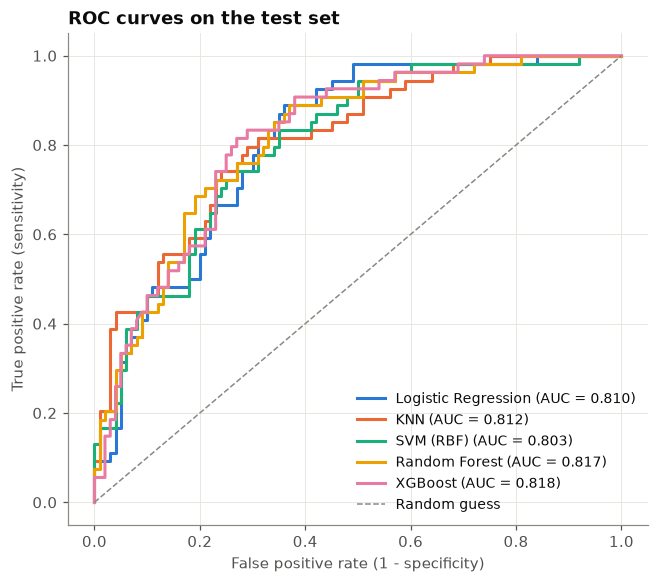

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 5.8))
for (name, proba), color in zip(probas.items(), PALETTE):
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
plt.savefig("images/roc_curves.png")
plt.show()

**Observation:** the five ROC curves almost overlap, and all lie well above the random-guess diagonal. Every model ranks patients in nearly the same order. The important decision is therefore **where to put the threshold**, which sets how many diabetic patients are caught compared with how many healthy patients get a false alarm.

### 8.3 Choosing a screening threshold

For **screening**, missing a diabetic patient (false negative) is worse than sending a healthy patient for an extra blood test (false positive). So instead of the default 0.5 threshold, I choose the threshold that reaches **at least 85% sensitivity**.

To keep the test set honest, I pick the threshold from **cross-validated (out-of-fold) predictions on the training set**, and only then apply it to the test set.

CV ROC-AUC: {'SVM (RBF)': 0.845, 'Logistic Regression': 0.845, 'XGBoost': 0.84, 'Random Forest': 0.84, 'KNN': 0.834}


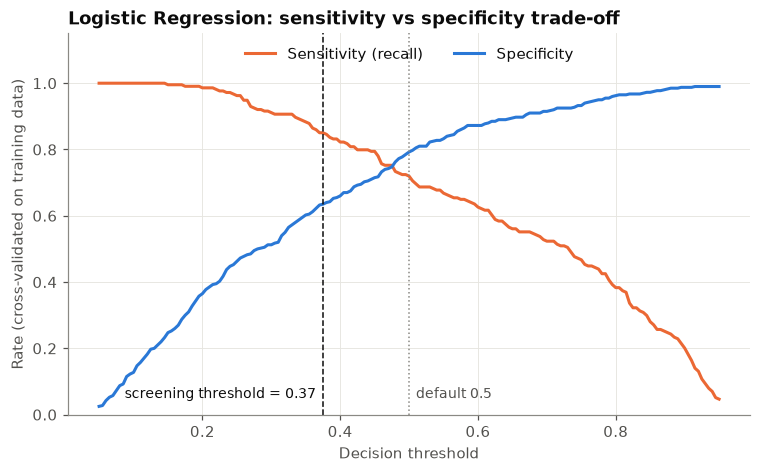

,Sensitivity,Specificity,Precision,Missed diabetics (FN),False alarms (FP)
Threshold,,,,,
Default (0.50),0.667,0.73,0.571,18,27
Screening (0.37),0.870,0.64,0.566,7,36


In [16]:
# Logistic Regression and SVM tie for the best CV ROC-AUC; in a tie I prefer the interpretable model
print("CV ROC-AUC:", {k: round(float(v), 3) for k, v in sorted(cv_scores.items(), key=lambda kv: -kv[1])})
BEST = "Logistic Regression"
best_pipe = best_models[BEST]

oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.linspace(0.05, 0.95, 181)
sens = np.array([recall_score(y_train, (oof >= t).astype(int)) for t in thresholds])
spec = np.array([((oof < t) & (y_train == 0)).sum() / (y_train == 0).sum() for t in thresholds])
screen_t = thresholds[sens >= 0.85].max()          # highest threshold that still gives >= 85% sensitivity

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, sens, color=PALETTE[1], label="Sensitivity (recall)")
ax.plot(thresholds, spec, color=PALETTE[0], label="Specificity")
ax.axvline(0.5, color="#8a8984", ls=":", lw=1)
ax.axvline(screen_t, color="#0b0b0b", ls="--", lw=1)
ax.text(screen_t - 0.01, 0.05, f"screening threshold = {screen_t:.2f}", fontsize=9, ha="right")
ax.text(0.51, 0.05, "default 0.5", fontsize=9, color="#52514e")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Rate (cross-validated on training data)")
ax.set_title(f"{BEST}: sensitivity vs specificity trade-off")
ax.set_ylim(0, 1.15)
ax.legend(loc="upper center", ncol=2)
plt.savefig("images/threshold_tradeoff.png")
plt.show()

test_proba = best_pipe.predict_proba(X_test)[:, 1]
compare = []
for label, t in [("Default (0.50)", 0.5), (f"Screening ({screen_t:.2f})", screen_t)]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    compare.append({"Threshold": label, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                    "Precision": tp / (tp + fp), "Missed diabetics (FN)": fn, "False alarms (FP)": fp})
pd.DataFrame(compare).set_index("Threshold").round(3)

**Observation:** the threshold chosen on the training data is **0.37**, the highest threshold that still gives at least 85% sensitivity. On the unseen test set it:
- raises **sensitivity from 0.667 to 0.870**, so the number of **missed diabetic patients drops from 18 to 7** (out of 54),
- lowers specificity from 0.73 to 0.64 (false alarms rise from 27 to 36), while precision stays about the same (0.57).

For screening, a false alarm only means one extra confirmatory blood test. Catching 11 more diabetic patients for 9 extra tests is a very good trade.

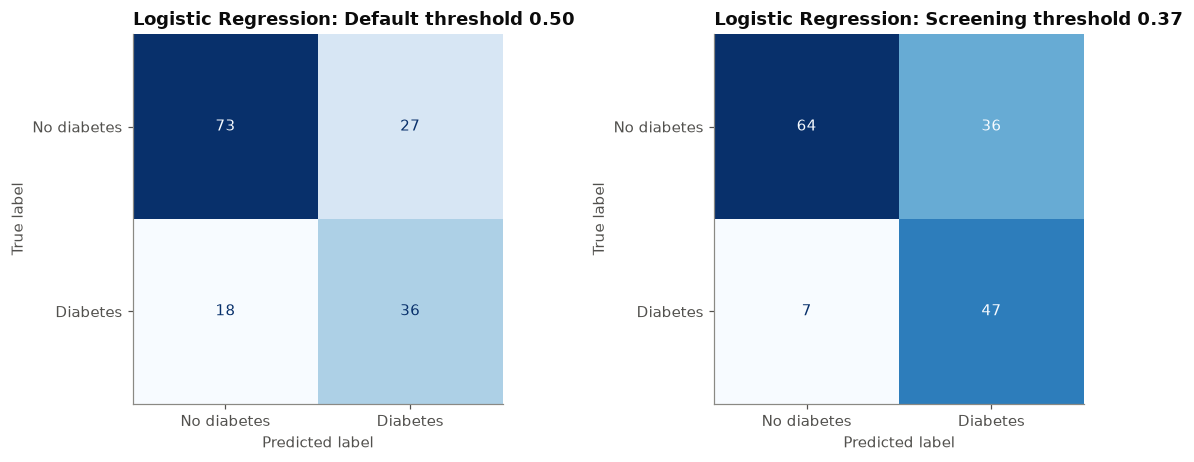

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (label, t) in zip(axes, [("Default threshold 0.50", 0.5), (f"Screening threshold {screen_t:.2f}", screen_t)]):
    cm = confusion_matrix(y_test, (test_proba >= t).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{BEST}: {label}")
    ax.grid(False)
plt.tight_layout()
plt.savefig("images/confusion_matrices.png")
plt.show()

**Observation:** the confusion matrices show the trade-off directly. Lowering the threshold moves patients from the *missed* cell (bottom-left) to the *caught* cell (bottom-right), at the cost of more healthy patients being sent for follow-up tests (top-right).

### 8.4 Feature importance

I look at importance in three complementary ways:
1. **Permutation importance** of the best model on the **test set**: how much ROC-AUC drops when one feature is randomly shuffled. This works for any model.
2. **Logistic Regression coefficients** on standardised features: the direction and strength of each effect.
3. **Random Forest impurity importance**.

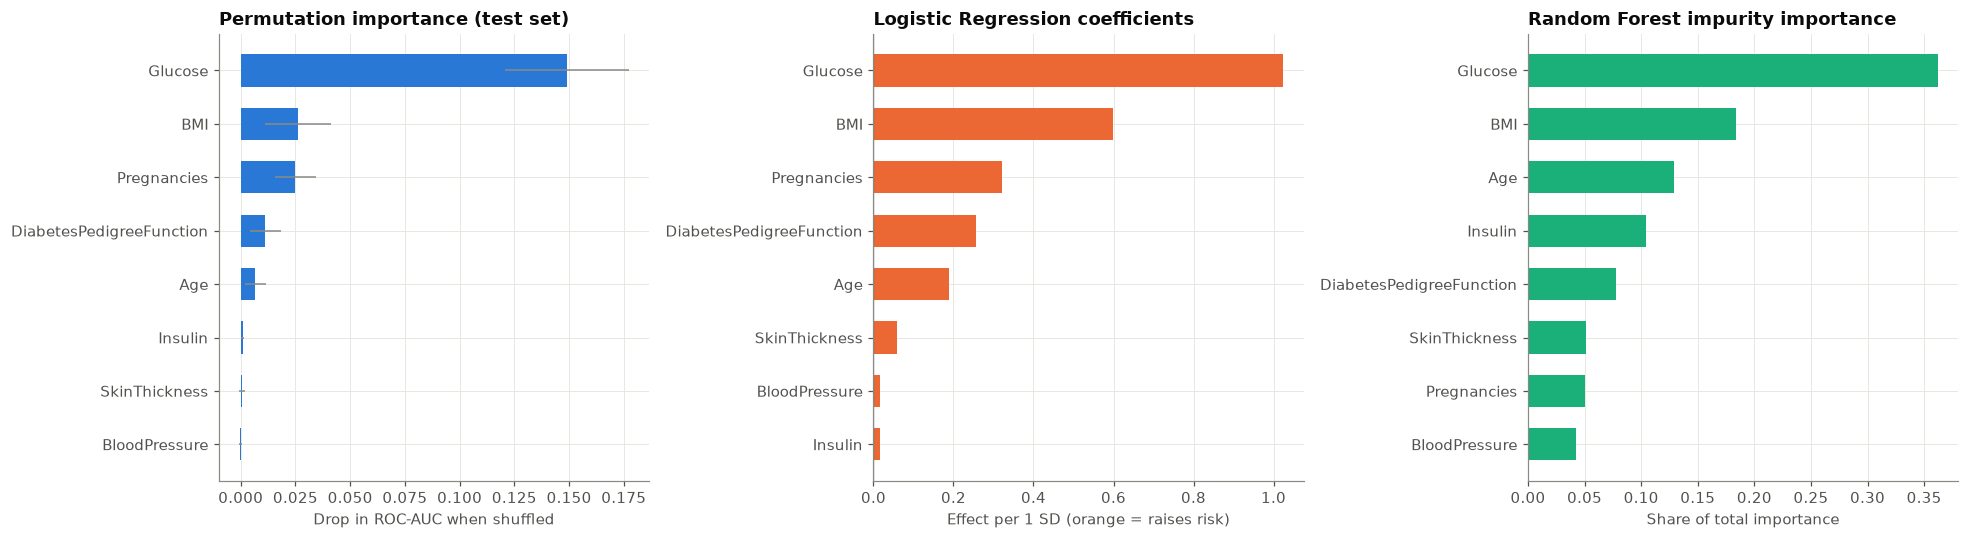

In [18]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
perm_std = pd.Series(perm.importances_std, index=X.columns).reindex(perm_imp.index)

lr_coef = pd.Series(best_models["Logistic Regression"].named_steps["model"].coef_[0], index=X.columns).sort_values()
rf_imp = pd.Series(best_models["Random Forest"].named_steps["model"].feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].barh(perm_imp.index, perm_imp.values, xerr=perm_std.values, color=PALETTE[0], height=0.6,
             error_kw={"ecolor": "#8a8984", "lw": 1})
axes[0].set_title("Permutation importance (test set)")
axes[0].set_xlabel("Drop in ROC-AUC when shuffled")

axes[1].barh(lr_coef.index, lr_coef.values, color=[PALETTE[1] if v > 0 else PALETTE[0] for v in lr_coef.values], height=0.6)
axes[1].axvline(0, color="#52514e", lw=0.8)
axes[1].set_title("Logistic Regression coefficients")
axes[1].set_xlabel("Effect per 1 SD (orange = raises risk)")

axes[2].barh(rf_imp.index, rf_imp.values, color=PALETTE[2], height=0.6)
axes[2].set_title("Random Forest impurity importance")
axes[2].set_xlabel("Share of total importance")
plt.tight_layout()
plt.savefig("images/feature_importance.png")
plt.show()

**Observation:** all three methods agree on the main drivers:
- **Glucose** is by far the most important feature. Shuffling it drops the model's test ROC-AUC by about **0.15**.
- **BMI** is clearly second, followed by **pregnancies**, the **diabetes pedigree function** (family history) and **age**.
- **Insulin, blood pressure and skin thickness add almost nothing** once glucose and BMI are known. Insulin and skin thickness are heavily imputed and correlated with glucose and BMI.
- The Random Forest ranks age and insulin somewhat higher. Trees capture non-linear effects and share importance differently between correlated features.

This matches medical knowledge. **High blood glucose and obesity are the key risk factors for type 2 diabetes**, and family history and age add to the risk.

## 9. Ethical data handling, bias and patient privacy

Health data is among the most sensitive personal data there is, and a diabetes risk model can directly influence medical care. These are the ethical points I considered.

### 9.1 Patient privacy and data protection
- **De-identification.** This dataset contains no names, IDs, addresses or dates. A real project would also need to check that combinations of features (for example a rare age and pregnancy count) cannot re-identify someone.
- **Legal frameworks.** Real patient data falls under laws such as **HIPAA** (US), the **GDPR** (EU, where health data is a "special category"), and India's **DPDP Act 2023**. These require a lawful basis or **informed consent**, **purpose limitation** and **data minimisation**: collect only the features the model needs.
- **Security.** Data should be stored encrypted with access control and audit logs, and never committed to public repositories. In this project only a public, de-identified research dataset is used. The notebook downloads it at runtime, and no patient data is stored in the repo.
- **Respect for the community.** The data comes from the Pima (Akimel O'odham) community, which has taken part in diabetes research for decades. Indigenous data-sovereignty principles (such as the **CARE principles**) ask researchers to use such data for the benefit of the community it came from.

### 9.2 Bias and fairness
- **Representation bias.** All patients are **women aged 21 or older from one Native American community**. The model **should not be assumed to work** for men, children, or other ethnic groups. It would have to be re-validated on local data before any real use.
- **Measurement bias.** Insulin and skin thickness are missing for many patients. Who gets tested is often not random, so imputation can hide systematic differences.
- **Label bias.** The diagnosis depends on who had access to testing and follow-up care.
- **Subgroup performance check.** Below I compare the model's sensitivity and specificity for **younger and older patients**. Different error rates across groups would mean unequal quality of care.

In [19]:
groups = pd.cut(X_test["Age"], bins=[20, 30, 90], labels=["Age 21-30", "Age 31+"])
screen_pred = (test_proba >= screen_t).astype(int)
fair = []
for g in groups.cat.categories:
    m = (groups == g).values
    yt, yp = y_test.values[m], screen_pred[m]
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    fair.append({"Group": g, "Patients": int(m.sum()), "Diabetes rate": yt.mean(),
                 "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                 "Specificity": tn / (tn + fp) if tn + fp else np.nan,
                 "Flagged as high risk": yp.mean()})
pd.DataFrame(fair).set_index("Group").round(3)

,Patients,Diabetes rate,Sensitivity,Specificity,Flagged as high risk
Group,,,,,
Age 21-30,89,0.202,0.667,0.718,0.360
Age 31+,65,0.554,0.972,0.448,0.785


**Observation:** the model behaves very differently across age groups.
- For patients **aged 31 and over**, it catches **97%** of diabetic patients, but it flags 79% of all older patients as high risk. Specificity is only **45%**, so many healthy older women would be sent for follow-up tests.
- For **21-30 year-olds**, it **misses a third of the diabetic patients** (sensitivity 0.67).

Part of this reflects the real difference in base rates (20% against 55% diabetes). It still means **younger diabetic patients are more likely to be overlooked**. The groups are small (18 and 36 diabetic patients in the test set), so the numbers are uncertain. Before real use I would check this on a larger dataset and discuss options such as **age-specific thresholds or recalibration** with clinicians.

### 9.3 Responsible use
- The model is a **decision-support tool for screening, not a diagnosis**. A positive flag should lead to a proper clinical test (such as HbA1c or a fasting glucose test), and the final decision stays with a clinician.
- Patients should be **told** when an algorithm is part of their care, and be able to ask for an explanation. Feature importance and the simple Logistic Regression model help here.
- Performance and fairness should be **monitored after deployment**, because populations and testing practices change over time.

## 10. Insights and conclusion

**Data cleaning**
- **652 impossible zero values** in Glucose, BloodPressure, SkinThickness, Insulin and BMI were treated as missing. Insulin alone was missing for 49% of patients.
- These values were imputed with **training-set medians**, and all features were **standardised**. Both steps run inside the model pipeline to avoid data leakage.

**Model comparison**
- All five models perform within about 0.01 ROC-AUC in cross-validation (0.834-0.845) and 0.015 on the test set (0.803-0.818). This dataset does not reward complex models.
- **XGBoost** had the best test scores at the default threshold (**ROC-AUC 0.818, F1 0.694, sensitivity 0.78**).
- **Logistic Regression** (tied best CV AUC 0.845, test AUC 0.810) was chosen as the **screening model** because it is interpretable.
- With a **screening threshold of 0.37**, chosen on training data only, Logistic Regression catches **87% of diabetic patients (47 of 54)** in the test set, missing 7 instead of 18.

**Key risk factors**
1. **Glucose** is the dominant predictor.
2. **BMI** (obesity) comes second.
3. **Pregnancies**, **family history** (pedigree function) and **age** follow.
4. Blood pressure, skin thickness and insulin add little once glucose and BMI are known.

**Ethics.** The model must be used as **decision support, not diagnosis**. It should only be applied to populations similar to the training data (adult Pima women) after local validation. The age-group check shows clearly different error rates for younger and older patients, which would need attention before deployment. Patient privacy must be protected through de-identification, consent, and secure handling.

**Next steps.** Validate on larger and more diverse datasets, add stronger clinical markers such as HbA1c, calibrate the probabilities, and monitor fairness over time.